# Data Exploration

## Description of all datasets
These datasets contain information about temperature measurements done around the world, starting in 1750 for average land temperatures and in 1850 for max and min land temperatures and global ocean and land temperatures.<br>
All measurements are in celsius.<br>
The uncertainty gives the 95% confidence interval around the measurement. So if a measurement of 1 degree is done with an uncertainty of 0.5, that means that with 95% confidence, the actual temperature is between 0.5 and 1.5.<br>

In [55]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine

In [2]:
def decompose_date(df: pd.DataFrame) -> pd.DataFrame:
    df["year"] = df["dt"].dt.year
    df["month"] = df["dt"].dt.month
    return df

engine = create_engine(
    "mysql+pymysql://root@localhost:3306/climate_watch"
)
df_city = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByCity", con=engine, parse_dates=["dt"])
df_city = decompose_date(df_city)

df_country = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByCountry", con=engine, parse_dates=["dt"])
df_country = decompose_date(df_country)

df_major_city = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByMajorCity", con=engine, parse_dates=["dt"])
df_major_city = decompose_date(df_major_city)

df_state = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByState", con=engine, parse_dates=["dt"])
df_state = decompose_date(df_state)

df_global = pd.read_sql("SELECT * FROM GlobalTemperatures", con=engine, parse_dates=["dt"])
df_global = decompose_date(df_global)

## City data

The city data consists of 7 columns: 
- Date of measurement
- Average temperature measured
- Uncertainty of temperature measurement
- City name
- Country name
- Latitude of measurement
- Longitude of measurement

Almost all values are present from 1900.

In [3]:
df_city["n"] = None
df_nr_of_empty_values = df_city.isna().groupby(df_city["year"]).sum()
df_nr_of_empty_values["nan_ratio"] = round(df_nr_of_empty_values["AverageTemperature"] / df_nr_of_empty_values["n"], 2)
with pd.option_context("Display.max_rows", None):
    display(df_nr_of_empty_values[["AverageTemperature", "n", "nan_ratio"]])

df_nr_of_empty_values["nan_ratio"].mean()

,AverageTemperature,n,nan_ratio
year,,,
1743,706,1412,0.50
1744,2122,8472,0.25
1745,5648,8472,0.67
1746,8472,8472,1.00
1747,8472,8472,1.00
1748,8472,8472,1.00
1749,8472,8472,1.00
1750,364,8484,0.04
1751,2395,8484,0.28


np.float64(0.06564575645756458)

In [7]:
def create_season_column(df: pd.DataFrame) -> pd.DataFrame:
    """
    This requires a numeric month column, and a latitude column to indicate northern and southern hemisphere.
    """
    northern_hemisphere_cond = df["Latitude"].str.endswith("N")
    northern_seasons = {
        1: "winter",
        2: "winter",
        3: "spring",
        4: "spring",
        5: "spring",
        6: "summer",
        7: "summer",
        8: "summer",
        9: "fall",
        10: "fall",
        11: "fall",
        12: "winter",
    }
    southern_seasons = {
        1: "summer",
        2: "summer",
        3: "fall",
        4: "fall",
        5: "fall",
        6: "winter",
        7: "winter",
        8: "winter",
        9: "spring",
        10: "spring",
        11: "spring",
        12: "summer",
    }

    df["season"] = np.where(
        northern_hemisphere_cond, 
        df["month"].map(northern_seasons), 
        df["month"].map(southern_seasons)
        )

    df["year_season"] = df["year"].astype(str) + "_" + df["season"]
    return df

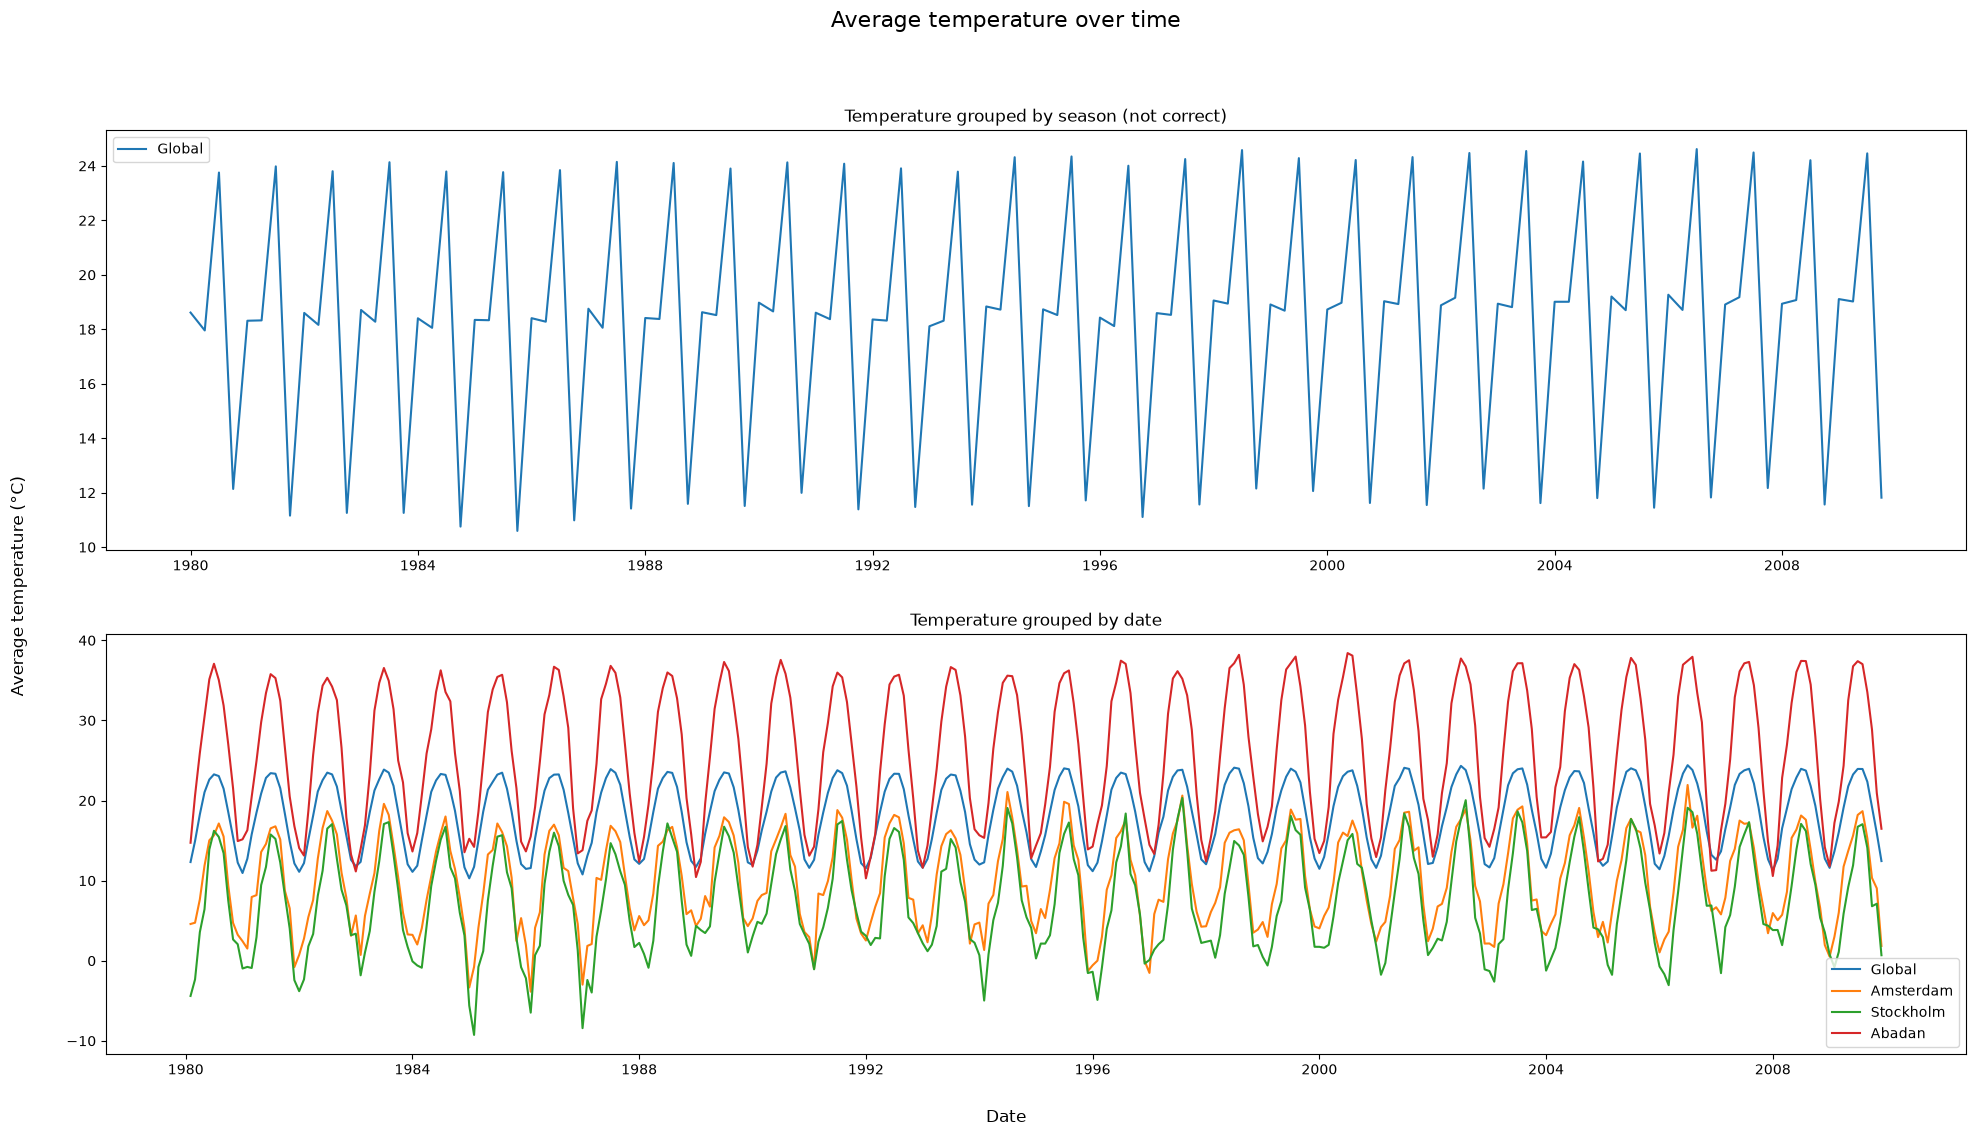

In [8]:
min_date = "1980-01-01"
max_date = "2010-01-01"

df_city_filter_date = df_city[
    (df_city["dt"] > min_date)
    & (df_city["dt"] < max_date)
]

df_city_sorted = df_city_filter_date.sort_values(["City", "Country", "dt"])
df_city_sorted = create_season_column(df_city_sorted)

# Temperature per city/global
df_city_vis_global_season = df_city_sorted[["year_season", "AverageTemperature"]].groupby(["year_season"]).mean()
df_city_vis_global_dates = df_city_sorted[["dt", "AverageTemperature"]].groupby(["dt"]).mean()
amsterdam_temps = df_city_sorted[df_city_sorted["City"] == "Amsterdam"]["AverageTemperature"]
stockholm_temps = df_city_sorted[df_city_sorted["City"] == "Stockholm"]["AverageTemperature"]
madrid_temps = df_city_sorted[df_city_sorted["City"] == "Madrid"]["AverageTemperature"]
kaapstad_temps = df_city_sorted[df_city_sorted["City"] == "Cape Town"]["AverageTemperature"]
sydney_temps = df_city_sorted[df_city_sorted["City"] == "Sydney"]["AverageTemperature"]
abadan_temps = df_city_sorted[df_city_sorted["City"] == "Abadan"]["AverageTemperature"]

year_seasons = df_city_sorted["year_season"].unique()
years = df_city_sorted["year"].unique()
dates = df_city_sorted["dt"].unique()

fig, ax = plt.subplots(2,1, figsize=(24,12))
fig.suptitle("Average temperature over time", fontsize=16)
fig.supylabel("Average temperature (°C)", x=0.085)
fig.supxlabel("Date", y=0.05)

# Upper subplot
ax[0].plot(df_city_vis_global_season.index, df_city_vis_global_season["AverageTemperature"], label="Global")

tick_positions = range(0, len(year_seasons), 16)
tick_labels = [year_seasons[i].split("_")[0] for i in tick_positions]
ax[0].set_xticks(tick_positions)
ax[0].set_xticklabels(tick_labels)
ax[0].legend()
ax[0].set_title("Temperature grouped by season (not correct)")


# Lower subplot
ax[1].plot(dates, df_city_vis_global_dates, label="Global")
ax[1].plot(dates, amsterdam_temps, label="Amsterdam")
ax[1].plot(dates, stockholm_temps, label="Stockholm")
ax[1].plot(dates, abadan_temps, label="Abadan")
# ax[1].plot(dates, madrid_temps, label="Madrid")
# ax[1].plot(dates, kaapstad_temps, label="Cape Town")
# ax[1].plot(dates, sydney_temps, label="Sydney")

ax[1].legend()
ax[1].set_title("Temperature grouped by date")

plt.show()

## Country data

The country dataset consists of 4 columns:
- Date of measurement
- Average temperature measured
- Uncertainty of measurement
- Country where measurement was taken

It has a similar missing value distribution to the city data, which is to be expected.

In [9]:
df_country["n"] = None
df_nr_of_empty_values = df_country.isna().groupby(df_country["year"]).sum()
df_nr_of_empty_values["nan_ratio"] = round(df_nr_of_empty_values["AverageTemperature"] / df_nr_of_empty_values["n"], 2)
with pd.option_context("Display.max_rows", None):
    display(df_nr_of_empty_values[["AverageTemperature", "n", "nan_ratio"]])

df_nr_of_empty_values["nan_ratio"].mean()

,AverageTemperature,n,nan_ratio
year,,,
1743,50,100,0.50
1744,150,600,0.25
1745,400,600,0.67
1746,600,600,1.00
1747,600,600,1.00
1748,600,600,1.00
1749,600,600,1.00
1750,0,600,0.00
1751,150,600,0.25


np.float64(0.08228782287822879)

C:\Users\Gebruiker\AppData\Local\Temp\ipykernel_13100\3035489198.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


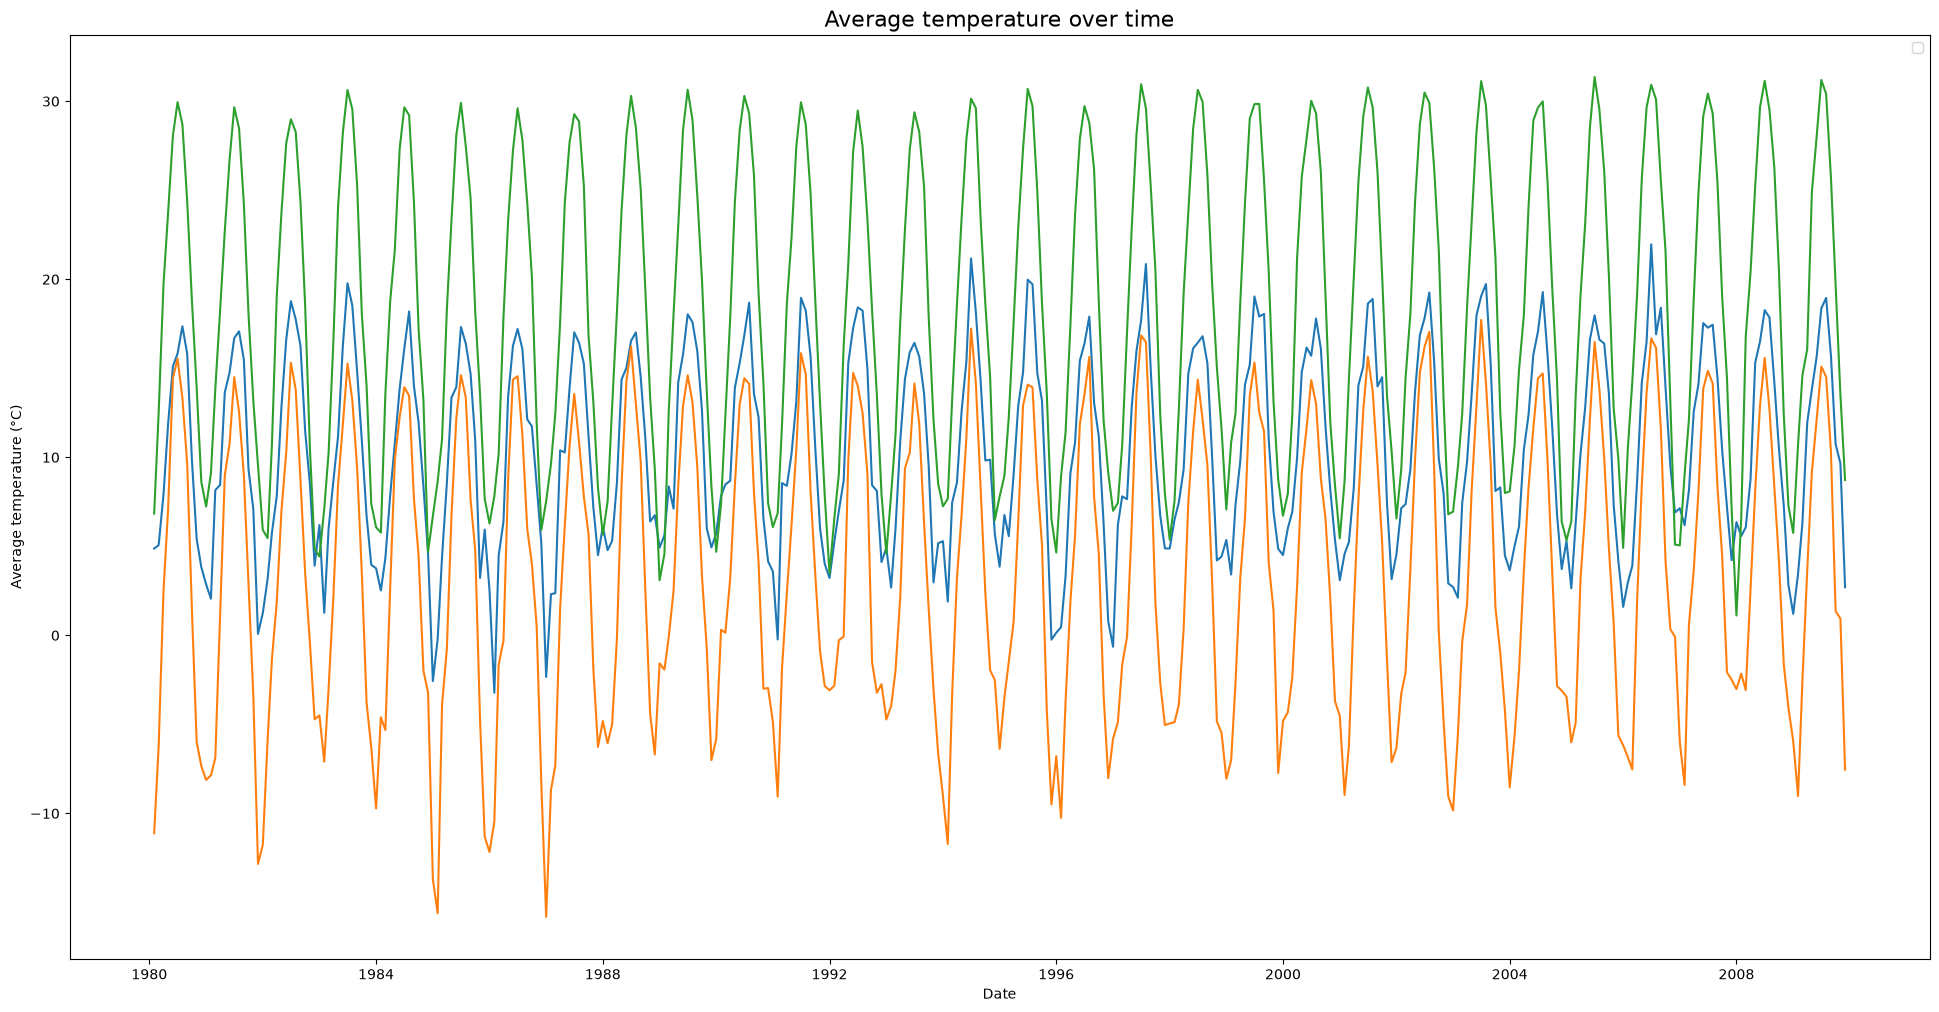

In [24]:
min_date = "1980-01-01"
max_date = "2010-01-01"

df_country_filter_date = df_country[
    (df_country["dt"] > min_date)
    & (df_country["dt"] < max_date)
]

df_country_sorted = df_country_filter_date.sort_values(["Country", "dt"])

# Temperature per country/global
df_country_vis_global_dates = df_country_sorted[["dt", "AverageTemperature"]].groupby(["dt"]).mean()
netherlands_temps = df_country_sorted[df_country_sorted["Country"] == "Netherlands"]["AverageTemperature"]
sweden_temps = df_country_sorted[df_country_sorted["Country"] == "Sweden"]["AverageTemperature"]
spain_temps = df_country_sorted[df_country_sorted["Country"] == "Spain"]["AverageTemperature"]
south_africa_temps = df_country_sorted[df_country_sorted["Country"] == "South Africa"]["AverageTemperature"]
australia_temps = df_country_sorted[df_country_sorted["Country"] == "Australia"]["AverageTemperature"]
iran_temps = df_country_sorted[df_country_sorted["Country"] == "Iran"]["AverageTemperature"]

dates = df_country_sorted["dt"].unique()

fig = plt.figure(figsize=(24,12))
plt.title("Average temperature over time", fontsize=16)
plt.ylabel("Average temperature (°C)", x=0.085)
plt.xlabel("Date", y=0.05)
plt.legend()

# plt.plot(dates, df_country_vis_global_dates, label="Global")
plt.plot(dates, netherlands_temps, label="The Netherlands")
plt.plot(dates, sweden_temps, label="Sweden")
# plt.plot(dates, spain_temps, label="Spain")
# plt.plot(dates, south_africa_temps, label="South Africa")
# plt.plot(dates, australia_temps, label="Australia")
plt.plot(dates, iran_temps, label="Iran")

plt.show()

## Major City

The major city dataset is identical to the city dataset, with the only difference being that only major cities are included. Therefore I will not create any visualisations, as they will be identical to the ones in the city dataset.<br>
It seems like the distribution of the missing values is also identical.

In [26]:
df_country["n"] = None
df_nr_of_empty_values = df_country.isna().groupby(df_country["year"]).sum()
df_nr_of_empty_values["nan_ratio"] = round(df_nr_of_empty_values["AverageTemperature"] / df_nr_of_empty_values["n"], 2)
with pd.option_context("Display.max_rows", None):
    display(df_nr_of_empty_values[["AverageTemperature", "n", "nan_ratio"]])

df_nr_of_empty_values["nan_ratio"].mean()

,AverageTemperature,n,nan_ratio
year,,,
1743,50,100,0.50
1744,150,600,0.25
1745,400,600,0.67
1746,600,600,1.00
1747,600,600,1.00
1748,600,600,1.00
1749,600,600,1.00
1750,0,600,0.00
1751,150,600,0.25


np.float64(0.08228782287822879)

## State dataset

As I don't think I will use this dataset much, the exploration is not extensive. 

In [39]:
with pd.option_context("Display.max_rows", None):
    display(df_state[["State", "Country"]].drop_duplicates().sort_values(["Country", "State"]).head(250))

,State,Country
48008,Australian Capital Territory,Australia
370749,New South Wales,Australia
393844,Northern Territory,Australia
461047,Queensland,Australia
519106,South Australia,Australia
538858,Tasmania,Australia
592052,Victoria,Australia
618401,Western Australia,Australia
0,Acre,Brazil
10697,Alagoas,Brazil


In [47]:
df_state["n"] = None
df_nr_of_empty_values = df_state.isna().groupby(df_state["year"]).sum()
df_nr_of_empty_values["nan_ratio"] = round(df_nr_of_empty_values["AverageTemperature"] / df_nr_of_empty_values["n"], 2)
with pd.option_context("Display.max_rows", None):
    display(df_nr_of_empty_values[["AverageTemperature", "n", "nan_ratio"]])

df_nr_of_empty_values["nan_ratio"].mean()

,AverageTemperature,n,nan_ratio
year,,,
1743,80,160,0.50
1744,240,960,0.25
1745,640,960,0.67
1746,960,960,1.00
1747,960,960,1.00
1748,960,960,1.00
1749,960,960,1.00
1750,120,960,0.12
1751,330,960,0.34


np.float64(0.06372693726937269)

## Global data

This dataset consists of 9 columns:
- Date of the measurement
- Average temperature on land
- Land temperature measurement uncertainty
- Maximum land temperature
- Maximum land temperature measurement uncertainty
- Minimum land temperature
- Minimum land temperature measurement uncertainty
- Average temperature on land and above the ocean
- Uncertainty of land and ocean temperature measurement

The only missing values for the average land temperature are in the early 1750s.<br>
The min, max, and land-ocean measurements started in 1850, and do not have any missing values from that point.

In [46]:
df_global["n"] = None
df_nr_of_empty_values = df_global.isna().groupby(df_global["year"]).sum()
df_nr_of_empty_values["nan_ratio"] = round(df_nr_of_empty_values["LandAverageTemperature"] / df_nr_of_empty_values["n"], 2)
with pd.option_context("Display.max_rows", 271):
    display(df_nr_of_empty_values)

df_nr_of_empty_values["nan_ratio"].mean()

,dt,LandAverageTemperature,LandAverageTemperatureUncertainty,LandMaxTemperature,LandMaxTemperatureUncertainty,LandMinTemperature,LandMinTemperatureUncertainty,LandAndOceanAverageTemperature,LandAndOceanAverageTemperatureUncertainty,year,month,n,nan_ratio
year,,,,,,,,,,,,,
1750,0,1,1,12,12,12,12,12,12,0,0,12,0.08
1751,0,5,5,12,12,12,12,12,12,0,0,12,0.42
1752,0,6,6,12,12,12,12,12,12,0,0,12,0.50
1753,0,0,0,12,12,12,12,12,12,0,0,12,0.00
1754,0,0,0,12,12,12,12,12,12,0,0,12,0.00
1755,0,0,0,12,12,12,12,12,12,0,0,12,0.00
1756,0,0,0,12,12,12,12,12,12,0,0,12,0.00
1757,0,0,0,12,12,12,12,12,12,0,0,12,0.00
1758,0,0,0,12,12,12,12,12,12,0,0,12,0.00


np.float64(0.0037593984962406013)

In [51]:
df_global.columns

Index(['dt', 'LandAverageTemperature', 'LandAverageTemperatureUncertainty',
       'LandMaxTemperature', 'LandMaxTemperatureUncertainty',
       'LandMinTemperature', 'LandMinTemperatureUncertainty',
       'LandAndOceanAverageTemperature',
       'LandAndOceanAverageTemperatureUncertainty', 'year', 'month', 'n'],
      dtype='str')

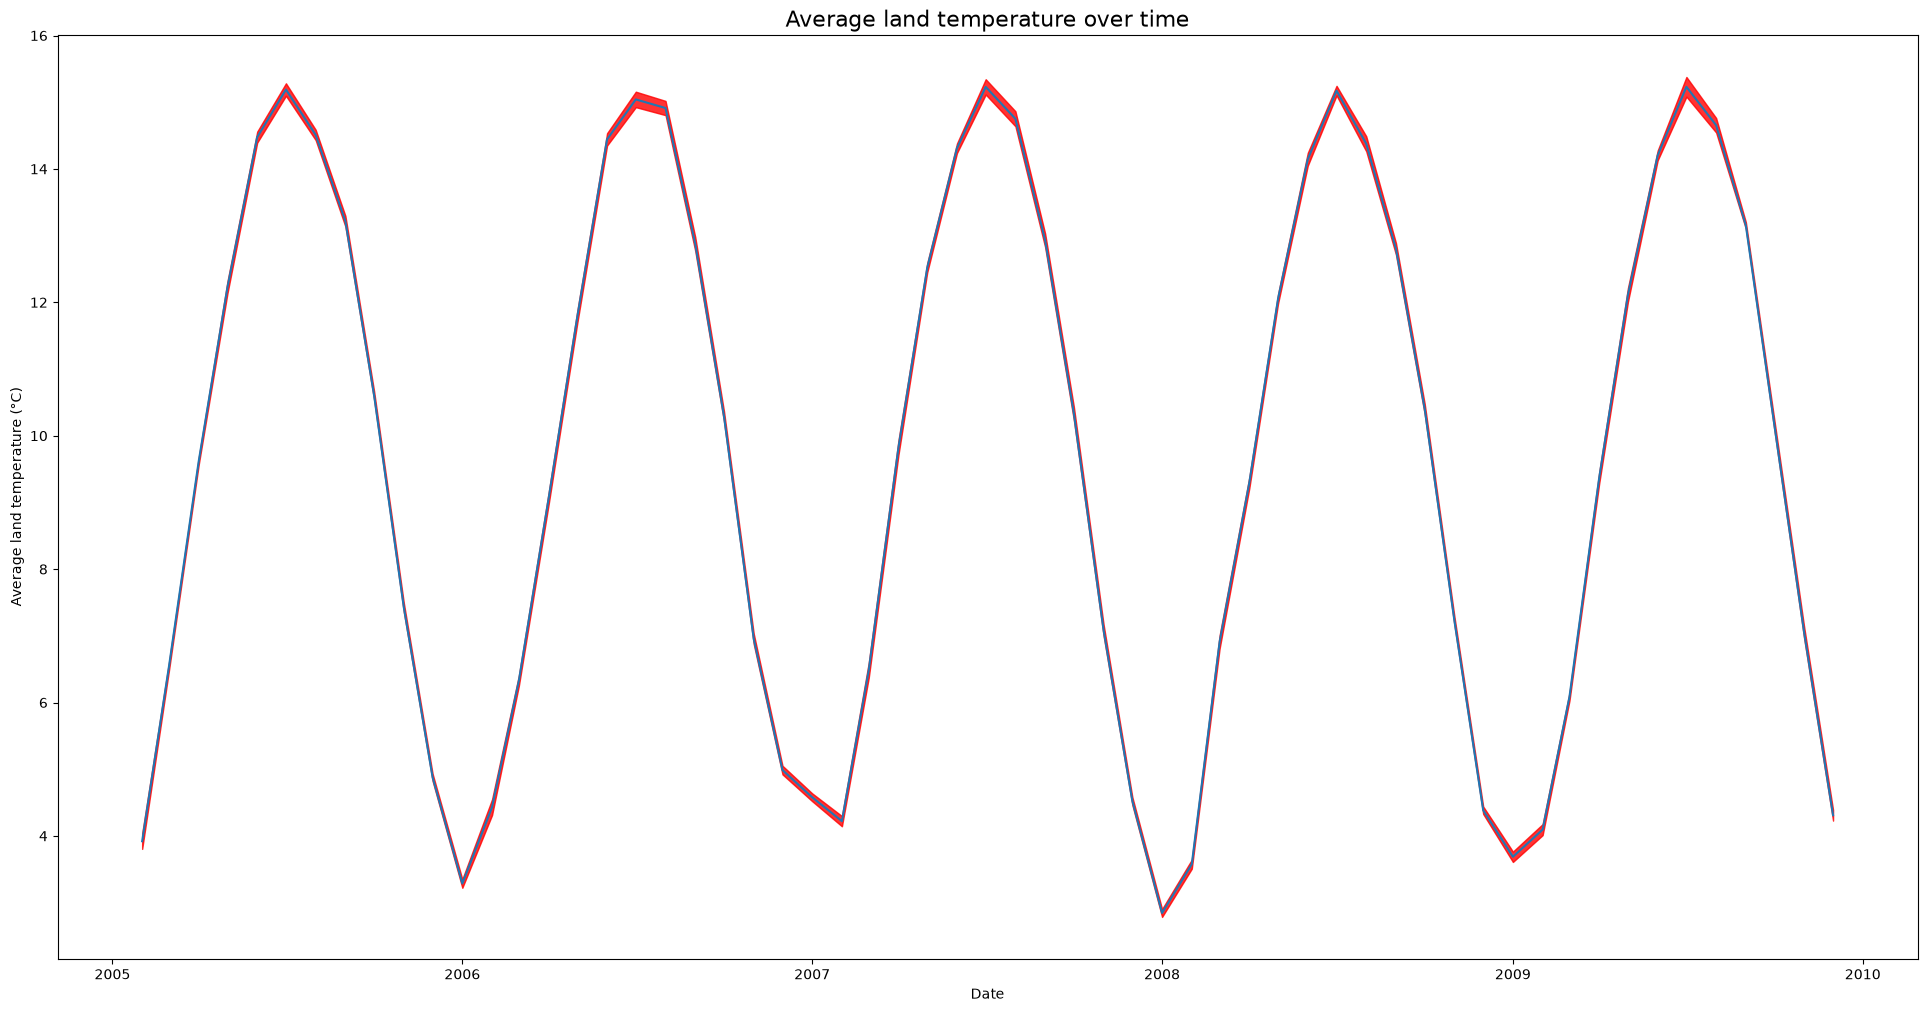

In [119]:
min_date = "2005-01-01"
max_date = "2010-01-01"

df_global_filter_date = df_global[
    (df_global["dt"] > min_date)
    & (df_global["dt"] < max_date)
]

df_global_sorted = df_global_filter_date.sort_values(["dt"])

# Temperature per country/global
df_global_vis = df_global_sorted[["dt", "LandAverageTemperature", "LandAverageTemperatureUncertainty"]].groupby(["dt"]).mean()

dates = df_global_sorted["dt"]
avg_land_temps = df_global_vis["LandAverageTemperature"]
avg_land_temps_uncer = df_global_vis["LandAverageTemperatureUncertainty"]


fig = plt.figure(figsize=(24,12))
plt.title("Average land temperature over time", fontsize=16)
plt.ylabel("Average land temperature (°C)", x=0.085)
plt.xlabel("Date", y=0.05)

plt.plot(dates, avg_land_temps)
plt.fill_between(
    dates, 
    avg_land_temps - avg_land_temps_uncer,
    avg_land_temps + avg_land_temps_uncer,
    alpha=0.8,
    label="Uncertainty",
    interpolate=True,
    color="Red"
    )

plt.show()

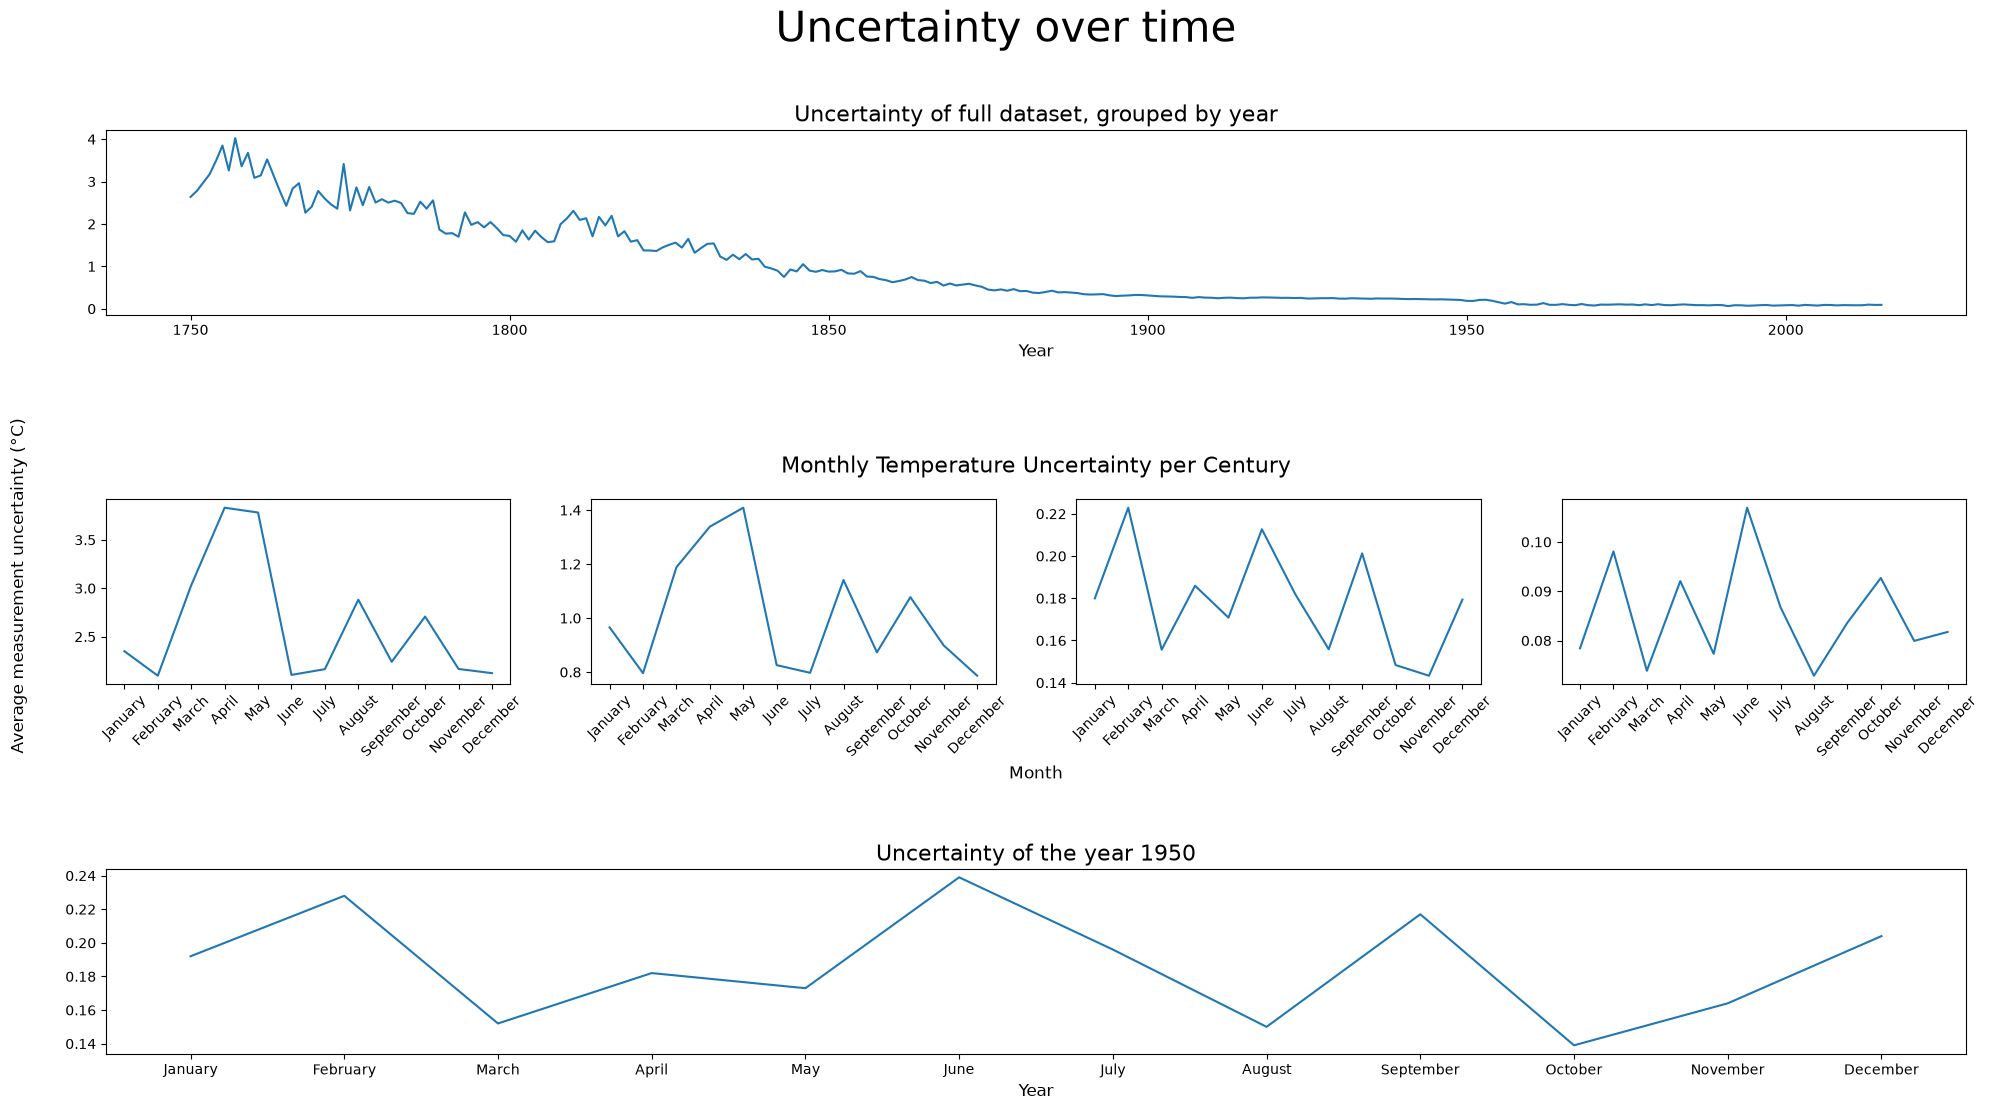

In [178]:
month_name_mapping = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December",
}

df_global["month_name"] = df_global["month"].map(month_name_mapping)

# Full data
df_global_sorted = df_global.sort_values("dt")

# Filter on each century
df_global_17 = df_global_sorted[
    (df_global_sorted["dt"] < "1800-01-01")
    ]
df_global_18 = df_global_sorted[
    (df_global_sorted["dt"] < "1900-01-01")
    & (df_global_sorted["dt"] >= "1800-01-01")
    ]
df_global_19 = df_global_sorted[
    (df_global_sorted["dt"] < "2000-01-01")
    & (df_global_sorted["dt"] >= "1900-01-01")
    ]
df_global_20 = df_global_sorted[
    (df_global_sorted["dt"] >= "2000-01-01")
    ]

# Single year analysis
year = 1950
df_global_single_year = df_global_sorted[
    (df_global_sorted["year"] == year)
]

# Group on year or month
df_global_group_yearly = df_global_sorted[["year", "LandAverageTemperatureUncertainty"]].groupby(["year"]).mean()
df_global_17_monthly = df_global_17[["month_name", "LandAverageTemperatureUncertainty"]].groupby(["month_name"]).mean()
df_global_18_monthly = df_global_18[["month_name", "LandAverageTemperatureUncertainty"]].groupby(["month_name"]).mean()
df_global_19_monthly = df_global_19[["month_name", "LandAverageTemperatureUncertainty"]].groupby(["month_name"]).mean()
df_global_20_monthly = df_global_20[["month_name", "LandAverageTemperatureUncertainty"]].groupby(["month_name"]).mean()
df_global_single_year_monthly = df_global_single_year[["month_name", "LandAverageTemperatureUncertainty"]].groupby(["month_name"]).mean()

# Create subplots in custom layout
fig = plt.figure(figsize=(24,12))
gs = fig.add_gridspec(3,4, hspace=1)


# Top plot
ax_big = fig.add_subplot(gs[0, :])
ax_big.plot(df_global_sorted["year"].unique(), df_global_group_yearly["LandAverageTemperatureUncertainty"])
ax_big.set_title("Uncertainty of full dataset, grouped by year", fontsize=16)
ax_big.set_xlabel("Year", fontsize=12)

# Middle subplots
ax_sub_1 = fig.add_subplot(gs[1,0])
ax_sub_2 = fig.add_subplot(gs[1,1])
ax_sub_3 = fig.add_subplot(gs[1,2])
ax_sub_4 = fig.add_subplot(gs[1,3])

ax_sub_1.plot(df_global_17["month_name"].unique(), df_global_17_monthly["LandAverageTemperatureUncertainty"])
ax_sub_2.plot(df_global_18["month_name"].unique(), df_global_18_monthly["LandAverageTemperatureUncertainty"])
ax_sub_3.plot(df_global_19["month_name"].unique(), df_global_19_monthly["LandAverageTemperatureUncertainty"])
ax_sub_4.plot(df_global_20["month_name"].unique(), df_global_20_monthly["LandAverageTemperatureUncertainty"])
ax_sub_2.set_title("Monthly Temperature Uncertainty per Century", fontsize=16, x=1.1, y=1.1)
ax_sub_2.set_xlabel("Month", fontsize=12, x=1.1, y=0.1)

# Bottom plot
ax_bottom = fig.add_subplot(gs[2, :])
ax_bottom.plot(df_global_single_year["month_name"].unique(), df_global_single_year_monthly["LandAverageTemperatureUncertainty"])
ax_bottom.set_title(f"Uncertainty of the year {year}", fontsize=16)
ax_bottom.set_xlabel("Year", fontsize=12)


# Rotate tick labels
for ax in [ax_sub_1, ax_sub_2, ax_sub_3, ax_sub_4]:
    ax.tick_params(axis="x", labelrotation=45)

fig.suptitle("Uncertainty over time", fontsize=30)
fig.supylabel("Average measurement uncertainty (°C)", x=0.085)

plt.show()